# Military & Commercial Aircraft Type Classifier (CNN)

**Course project – CS471 | Tushar Bhatia & Isabella Peterson**

## Purpose
Given an image of an aircraft (from the ground, the air, or overhead/satellite imagery), predict **which aircraft type it is** (e.g. `F16`, `Ka52`, `Boeing 737`).
Knowing the type tells a decision-maker the aircraft's capabilities, which supports time-sensitive decisions.

## How this notebook addresses the instructor feedback
| Required revision | How it is handled here |
|---|---|
| 1. Identify the categories the model predicts | The **114 aircraft-type classes** in the dataset (103 military + 11 commercial). The exact class list is printed in Section 3 and any class removed for having too few examples is reported in Section 4. |
| 2. Clarify: train a CNN or adapt a pretrained model? | **Both, and we compare them.** (a) A small CNN trained **from scratch**, and (b) a **pretrained ResNet-18 fine-tuned** (transfer learning). Sections 9–10. |
| 3. Define train/test separation + a simple comparison baseline | Images are split **by source image** into train / validation / test (70/15/15) so no photo appears in more than one split (Section 6). Two simple baselines – *majority class* and *random guessing by class frequency* – are in Section 8. |
| 4. Identify aircraft types, not friend/enemy | The label is **only the aircraft type**. No affiliation is predicted or inferred anywhere in this notebook. |

## Evaluation plan (from the project scope + feedback)
* **Confusion matrix** (full 114x114 + zoomed view + most-confused pairs) to find strengths/weaknesses of the model.
* Top-1 accuracy, **top-5 accuracy**, **macro-F1** (macro-F1 matters because classes are imbalanced), and per-class precision/recall.
* The test set is used **exactly once**, at the very end (Section 11), after all model choices are made on the validation set.
* Breakdown of performance by object size in the image (a proxy for "far away / small" vs "close up") since the final project will explore more image conditions.

## Overall pipeline
```
per-image CSV annotations  ->  one table (1 row per aircraft bounding box)
   -> filter tiny boxes / very rare classes
   -> split BY IMAGE into train / val / test
   -> crop each box, resize to a fixed square, cache to disk
   -> train CNN (scratch) and CNN (pretrained)  [select with validation set]
   -> evaluate ONCE on the test set vs. baselines
```

## 1. Setup
Install dependencies (only needed once; skip the cell if already installed) and import libraries.

In [1]:
# Run once in a notebook cell if packages are missing (remove the leading '#'):
%pip install torch torchvision pandas numpy matplotlib scikit-learn pillow tqdm seaborn
# (For GPU support, install the CUDA build of PyTorch from https://pytorch.org/get-started/locally/)

  Using cached setuptools-84.2.1-py3-none-any.whl.metadata (6.6 kB)
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.0/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ---------------------------------------- 0.3/126.7 MB ? eta -:--:--
   ------

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.

[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os, glob, random, time, json
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models

from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import (confusion_matrix, classification_report,
                             accuracy_score, f1_score, top_k_accuracy_score)

print("PyTorch:", torch.__version__)

PyTorch: 2.15.0+cpu


## 2. Configuration
All tunable settings live in one place. **Edit `DATA_DIR` if your path differs.**
A `SEED` makes the random split and training reproducible (important for a fair comparison and for re-running the notebook).

In [3]:
# ---------- Paths ----------
DATA_DIR  = Path(r"C:\Users\C27Isabella.Peterson\Downloads\archive\dataset")   # images (.jpg) + per-image annotation (.csv)
CACHE_DIR = Path("crop_cache")      # where our resized crops are stored (created automatically)
OUT_DIR   = Path("outputs")         # saved model, figures, metrics
CACHE_DIR.mkdir(exist_ok=True); OUT_DIR.mkdir(exist_ok=True)

# ---------- Data filtering ----------
MIN_BOX_PIXELS   = 32     # drop boxes whose shorter side is < this many pixels (too small to be recognizable)
MIN_CROPS_PER_CLASS = 20  # drop classes with fewer examples than this (cannot be learned or fairly tested)
BOX_PADDING      = 0.05   # add 5% context around each bounding box when cropping

# ---------- Split (by source image) ----------
# StratifiedGroupKFold with 7 folds: 1 fold (~14%) -> test, 1 fold (~14%) -> val, remaining 5 (~72%) -> train
N_SPLITS = 7
SEED     = 42

# ---------- Model / training ----------
IMG_SIZE   = 160          # every crop becomes IMG_SIZE x IMG_SIZE
BATCH_SIZE = 64
EPOCHS_SCRATCH    = 25
EPOCHS_PRETRAINED = 12
NUM_WORKERS = 0           # 0 is the safest on Windows / Jupyter. Increase (e.g. 4) if loading is slow.

def set_seed(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
set_seed()

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", DEVICE)

Using device: cpu


## 3. Load the annotations
Each image in `dataset/` has a CSV with the same filename. Each row is **one aircraft** (a bounding box and a class). One image can contain several aircraft, sometimes of different types.
We read all CSVs and stack them into one table with **one row per aircraft**.

In [4]:
csv_files = sorted(glob.glob(str(DATA_DIR / "*.csv")))
print(f"Found {len(csv_files):,} annotation files")
assert len(csv_files) > 0, "No CSV files found - check DATA_DIR"

def read_csv_safe(p):
    try:
        return pd.read_csv(p)
    except Exception as e:
        print("Skipping unreadable file:", p, e); return None

with ThreadPoolExecutor(8) as ex:
    frames = [f for f in tqdm(ex.map(read_csv_safe, csv_files), total=len(csv_files)) if f is not None]
ann = pd.concat(frames, ignore_index=True)

# Add the path of the matching image
ann["img_path"] = ann["filename"].apply(lambda f: str(DATA_DIR / f"{f}.jpg"))
ann["exists"]   = ann["img_path"].apply(os.path.exists)
print("Annotation rows (aircraft boxes):", len(ann))
print("Rows whose image file is missing:", (~ann["exists"]).sum())
ann = ann[ann["exists"]].drop(columns="exists").reset_index(drop=True)
ann.head()

Found 25,386 annotation files


  0%|          | 0/25386 [00:00<?, ?it/s]

Annotation rows (aircraft boxes): 45435
Rows whose image file is missing: 0


,filename,width,height,class,xmin,ymin,xmax,ymax,img_path
0,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,1380,1904,1522,2014,C:\Users\C27Isabella.Peterson\Downloads\archiv...
1,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,1809,1625,1958,1759,C:\Users\C27Isabella.Peterson\Downloads\archiv...
2,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,2400,1571,2532,1727,C:\Users\C27Isabella.Peterson\Downloads\archiv...
3,0000e97ea2d086d6759b19b288a8a72c,4928,3264,Mi28,3935,1772,4100,1891,C:\Users\C27Isabella.Peterson\Downloads\archiv...
4,00010041af654d0b8e1e16c824fa9867,1360,2048,UH60,835,526,1233,741,C:\Users\C27Isabella.Peterson\Downloads\archiv...


### Exploratory data analysis (EDA)
Before modeling we look at the data: how many images/boxes, how many classes, how imbalanced the classes are, and how big the boxes are.

Images: 25,386 | Boxes: 45,435 | Classes: 114

Most common classes:
 class
F16       2115
F18       1856
C130      1619
F15       1602
F35       1599
J20        940
V22        936
Rafale     856
EF2000     855
C2         842
Name: count, dtype: int64

Rarest classes:
 class
MQ35    79
X29     76
XQ58    75
MQ28    75
V280    63
J50     56
WZ10    42
Z21     31
MQ20    28
WZ9     21
Name: count, dtype: int64


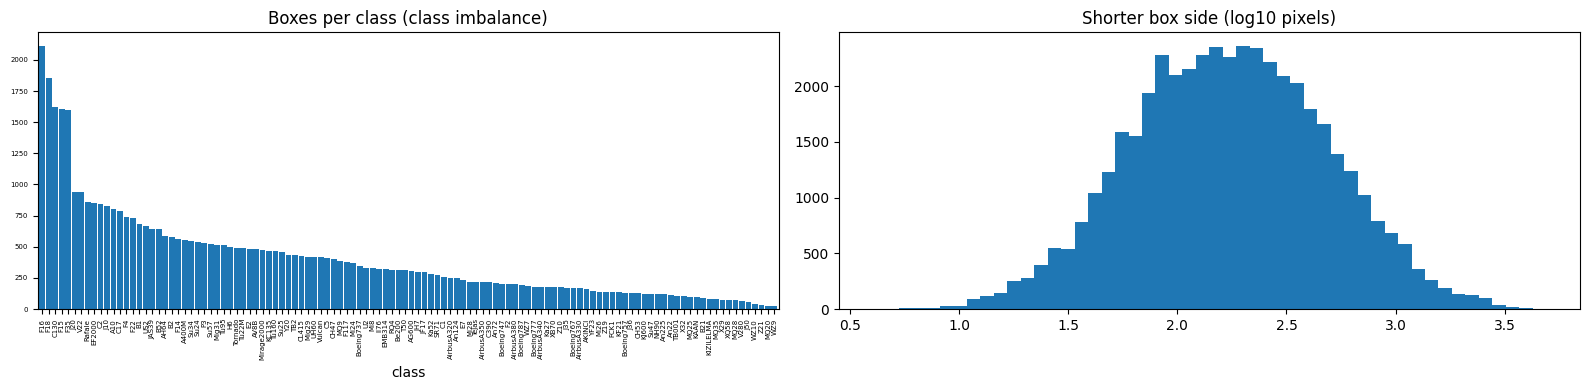

In [5]:
ann["box_w"] = ann.xmax - ann.xmin
ann["box_h"] = ann.ymax - ann.ymin
ann["box_short"] = ann[["box_w","box_h"]].min(axis=1)

print(f"Images: {ann.filename.nunique():,} | Boxes: {len(ann):,} | Classes: {ann['class'].nunique()}")
counts = ann["class"].value_counts()
print("\nMost common classes:\n", counts.head(10))
print("\nRarest classes:\n", counts.tail(10))

fig, ax = plt.subplots(1, 2, figsize=(16, 4))
counts.plot(kind="bar", ax=ax[0], width=0.9); ax[0].set_title("Boxes per class (class imbalance)"); ax[0].tick_params(labelsize=5)
ax[1].hist(np.log10(ann.box_short.clip(lower=1)), bins=50); ax[1].set_title("Shorter box side (log10 pixels)")
plt.tight_layout(); plt.show()

## 4. Filter the data
* **Tiny boxes** (very far-away aircraft) are only a few pixels wide and carry almost no information. We drop boxes smaller than `MIN_BOX_PIXELS`.
* **Very rare classes** can't be learned or fairly evaluated (they could have 0 examples in the test set). We drop classes below `MIN_CROPS_PER_CLASS` and **report them** so it's documented. Lower the threshold to keep more classes.
* Boxes with invalid coordinates are removed.

In [6]:
n0 = len(ann)
df = ann[(ann.xmax > ann.xmin) & (ann.ymax > ann.ymin) & (ann.box_short >= MIN_BOX_PIXELS)].copy()
print(f"Removed {n0-len(df):,} tiny/invalid boxes")

cls_counts = df["class"].value_counts()
rare = cls_counts[cls_counts < MIN_CROPS_PER_CLASS]
print(f"Removing {len(rare)} rare classes (< {MIN_CROPS_PER_CLASS} examples): {sorted(rare.index.tolist())}")
df = df[~df["class"].isin(rare.index)].reset_index(drop=True)

# Convert class names -> integer labels (what the neural network needs)
classes = sorted(df["class"].unique())
class_to_idx = {c:i for i,c in enumerate(classes)}
df["label"] = df["class"].map(class_to_idx)
NUM_CLASSES = len(classes)
print(f"\nFinal dataset: {len(df):,} boxes, {df.filename.nunique():,} images, {NUM_CLASSES} classes")
print("Classes the model will predict:\n", classes)
json.dump(classes, open(OUT_DIR/"classes.json","w"))

Removed 2,197 tiny/invalid boxes
Removing 0 rare classes (< 20 examples): []

Final dataset: 43,238 boxes, 24,605 images, 114 classes
Classes the model will predict:
 ['A10', 'A400M', 'AG600', 'AH64', 'AKINCI', 'AV8B', 'AirbusA320', 'AirbusA330', 'AirbusA340', 'AirbusA350', 'AirbusA380', 'An124', 'An22', 'An225', 'An72', 'B1', 'B2', 'B21', 'B52', 'Be200', 'Boeing737', 'Boeing747', 'Boeing757', 'Boeing767', 'Boeing777', 'Boeing787', 'C1', 'C130', 'C17', 'C2', 'C390', 'C5', 'CH47', 'CH53', 'CL415', 'E2', 'E7', 'EF2000', 'EMB314', 'F117', 'F14', 'F15', 'F16', 'F18', 'F2', 'F22', 'F35', 'F4', 'FCK1', 'H6', 'Il76', 'J10', 'J20', 'J35', 'J36', 'J50', 'JAS39', 'JF17', 'JH7', 'KAAN', 'KC135', 'KF21', 'KIZILELMA', 'KJ600', 'Ka27', 'Ka52', 'MQ20', 'MQ25', 'MQ28', 'MQ35', 'MQ9', 'Mi24', 'Mi26', 'Mi28', 'Mi8', 'Mig29', 'Mig31', 'Mirage2000', 'NH90', 'P3', 'RQ4', 'Rafale', 'SR71', 'Su24', 'Su25', 'Su34', 'Su47', 'Su57', 'T50', 'TB001', 'TB2', 'Tejas', 'Tornado', 'Tu160', 'Tu22M', 'Tu95', 'U2', 'UH6

## 5. Why we split by *image*, not by box
Many images contain several aircraft, and the dataset may contain near-duplicate photos of the same scene. If we randomly split individual boxes, **crops from the same photo can land in both train and test**, so the model would "recognise" the background/photo rather than the aircraft and our test score would be inflated (**data leakage**).

So we assign **whole images** to a split. `StratifiedGroupKFold` keeps every image (the *group*) in one split while keeping the class proportions similar in each split (*stratified*).

## 6. Train / validation / test split
* **Train (~72%)** – the model learns from these.
* **Validation (~14%)** – used to pick the best epoch/model and tune settings.
* **Test (~14%)** – never touched until the final evaluation.

No image overlap between splits  ✓
       images  boxes  classes
split                        
test     3488   6178      114
train   17599  30883      114
val      3518   6177      114


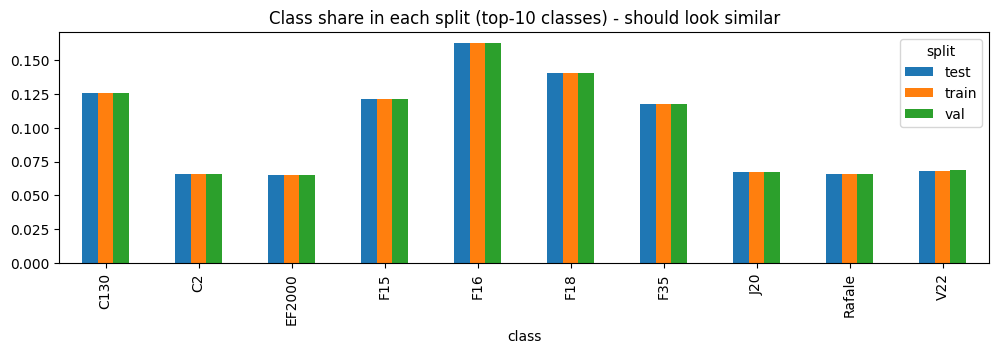

In [7]:
sgkf = StratifiedGroupKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
folds = [te for _, te in sgkf.split(df, df["label"], groups=df["filename"])]

df["split"] = "train"
df.loc[folds[0], "split"] = "test"
df.loc[folds[1], "split"] = "val"

# ---- Sanity checks: no image may appear in more than one split ----
imgs = {s:set(df[df.split==s].filename) for s in ["train","val","test"]}
assert not (imgs["train"] & imgs["val"]) and not (imgs["train"] & imgs["test"]) and not (imgs["val"] & imgs["test"]), "LEAKAGE!"
print("No image overlap between splits  \u2713")

summary = df.groupby("split").agg(images=("filename","nunique"), boxes=("label","size"), classes=("label","nunique"))
print(summary)

# Class balance across splits (fraction of each split belonging to its 10 biggest classes)
top = df["class"].value_counts().head(10).index
prop = (df[df["class"].isin(top)].groupby(["split","class"]).size().unstack(0)).apply(lambda c: c/c.sum())
prop.plot(kind="bar", figsize=(12,3), title="Class share in each split (top-10 classes) - should look similar"); plt.show()

## 7. Crop every aircraft and cache it
For classification we feed the CNN a **crop of each aircraft** (using its bounding box) rather than the whole image, which may contain other aircraft.
Each crop is:
1. cut out with a little padding for context,
2. **letterboxed** to a square (padded, *not* stretched, so aircraft shapes — e.g. wing sweep — aren't distorted),
3. resized to `IMG_SIZE x IMG_SIZE` and saved.

Doing this once up-front makes training much faster than re-decoding large JPEGs every epoch. This is equivalent to the dataset's `crop` folder, except that **we control the split**, which prevents leakage.

In [8]:
def letterbox(img, size):
    # Resize keeping aspect ratio and pad to a square with a neutral grey background.
    w, h = img.size; s = size / max(w, h)
    nw, nh = max(1, round(w*s)), max(1, round(h*s))
    img = img.resize((nw, nh), Image.BILINEAR)
    canvas = Image.new("RGB", (size, size), (124, 116, 104))
    canvas.paste(img, ((size-nw)//2, (size-nh)//2))
    return canvas

def process_image(item):
    # Open one source image ONCE and save all of its aircraft crops.
    path, rows = item
    try:
        im = Image.open(path).convert("RGB")
    except Exception as e:
        return []
    W, H = im.size; out = []
    for idx, r in rows:
        bw, bh = r.xmax-r.xmin, r.ymax-r.ymin
        x0 = max(0, int(r.xmin - BOX_PADDING*bw)); y0 = max(0, int(r.ymin - BOX_PADDING*bh))
        x1 = min(W, int(r.xmax + BOX_PADDING*bw)); y1 = min(H, int(r.ymax + BOX_PADDING*bh))
        if x1 <= x0 or y1 <= y0: continue
        crop = letterbox(im.crop((x0,y0,x1,y1)), IMG_SIZE)
        p = CACHE_DIR / f"{idx}.jpg"
        crop.save(p, quality=95); out.append((idx, str(p)))
    return out

if not (CACHE_DIR / "done.flag").exists():
    items = [(p, list(g.iterrows())) for p, g in df.groupby("img_path")]
    results = []
    with ThreadPoolExecutor(8) as ex:
        for res in tqdm(ex.map(process_image, items), total=len(items), desc="Cropping"):
            results.extend(res)
    pd.DataFrame(results, columns=["idx","crop_path"]).to_csv(CACHE_DIR/"index.csv", index=False)
    (CACHE_DIR / "done.flag").write_text(f"IMG_SIZE={IMG_SIZE}")
else:
    print("Crop cache already built - reusing it. (Delete the crop_cache folder if you change IMG_SIZE/filters.)")

idx_map = pd.read_csv(CACHE_DIR/"index.csv").set_index("idx")["crop_path"]
df["crop_path"] = df.index.map(idx_map)
df = df.dropna(subset=["crop_path"]).reset_index(drop=True)
print("Crops available:", len(df))

Cropping:   0%|          | 0/24605 [00:00<?, ?it/s]

Crops available: 43238


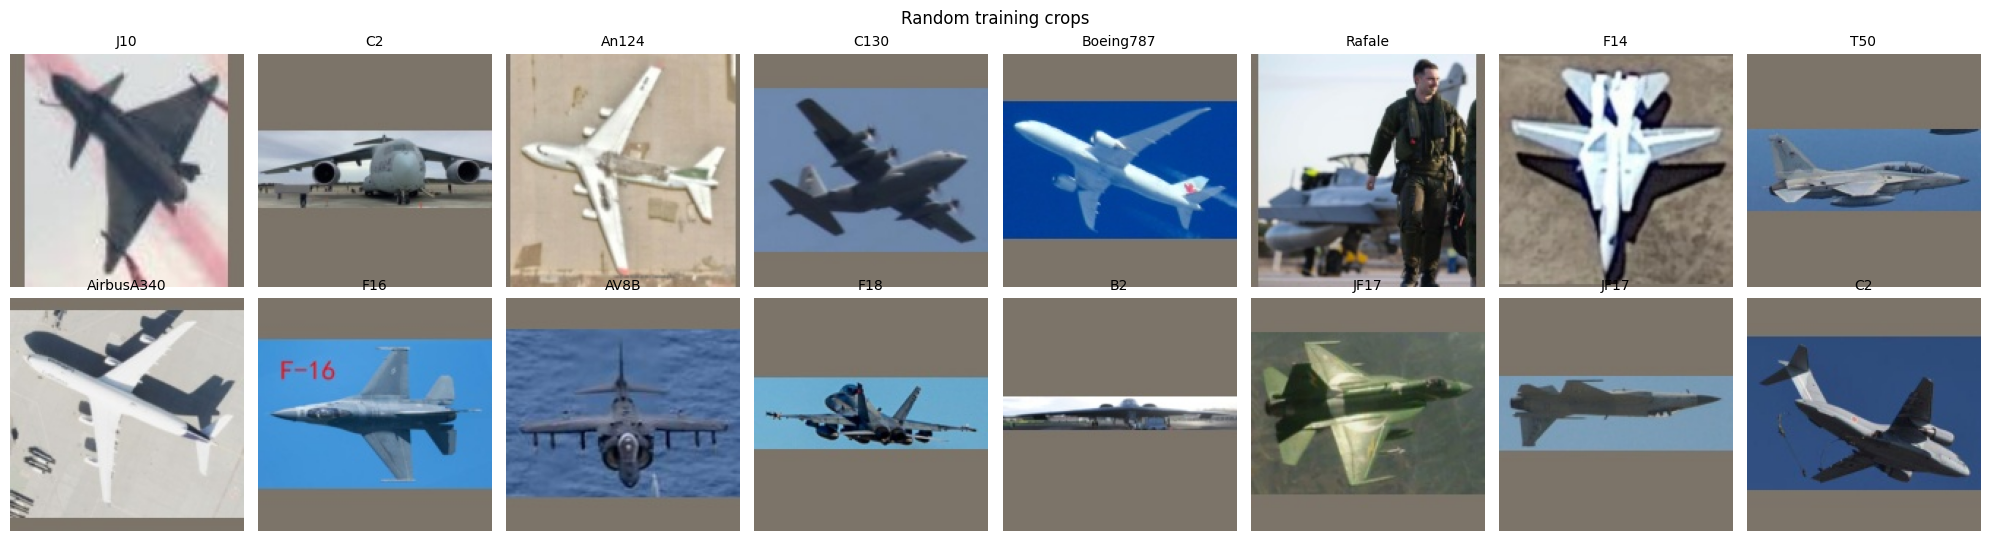

In [9]:
# Visual check: random training crops with their labels (make sure labels match what you see!)
sample = df[df.split=="train"].sample(16, random_state=SEED)
fig, axes = plt.subplots(2, 8, figsize=(20, 5.5))
for ax, (_, r) in zip(axes.ravel(), sample.iterrows()):
    ax.imshow(Image.open(r.crop_path)); ax.set_title(r["class"], fontsize=10); ax.axis("off")
plt.suptitle("Random training crops"); plt.tight_layout(); plt.show()

## 8. Simple comparison baselines
Before training any neural network, we measure how well **trivial strategies** do, so we can show the CNN is really learning something:

* **Majority-class baseline** – always predict the most common training class.
* **Random-by-frequency baseline** – guess a class at random, weighted by how common it is in training.

With 100+ classes, chance is very low. The CNN must beat both by a wide margin.

In [10]:
train_df, val_df, test_df = [df[df.split==s].reset_index(drop=True) for s in ["train","val","test"]]

# Baseline 1: majority class
majority = train_df["label"].mode()[0]
base_major_acc = (val_df["label"] == majority).mean()
base_major_f1  = f1_score(val_df["label"], np.full(len(val_df), majority), average="macro", zero_division=0)

# Baseline 2: random guess weighted by training class frequency
rng = np.random.default_rng(SEED)
class_freq = train_df["label"].value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0).values
rand_pred = rng.choice(NUM_CLASSES, size=len(val_df), p=class_freq)
base_rand_acc = accuracy_score(val_df["label"], rand_pred)
base_rand_f1  = f1_score(val_df["label"], rand_pred, average="macro", zero_division=0)

baselines = pd.DataFrame({"val_accuracy":[base_major_acc, base_rand_acc],
                          "val_macro_F1":[base_major_f1, base_rand_f1]},
                         index=[f"Majority class ({classes[majority]})","Random (by class frequency)"])
baselines

,val_accuracy,val_macro_F1
Majority class (F16),0.046948,0.000787
Random (by class frequency),0.013761,0.006593


## 9. Data loading and augmentation
* **Training transforms** include random augmentation (horizontal flip, small rotation, colour jitter, small zoom/shift). Augmentation simulates different viewing conditions (lighting, angle, haze) and reduces overfitting.
* **Validation/test transforms** are deterministic (no augmentation) so evaluation is repeatable.
* Pixels are normalised with ImageNet statistics. This is required for the pretrained model and harmless for the scratch CNN.

In [11]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.7, 1.0), ratio=(0.9, 1.1)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(10, fill=(124,116,104)),
    transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])
eval_tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize(MEAN, STD)])

class AircraftDataset(Dataset):
    # Returns (image_tensor, integer_label) for one cached crop.
    def __init__(self, frame, tf): self.paths = frame.crop_path.tolist(); self.labels = frame.label.tolist(); self.tf = tf
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        return self.tf(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

train_loader = DataLoader(AircraftDataset(train_df, train_tf), BATCH_SIZE, shuffle=True,  num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(AircraftDataset(val_df,   eval_tf),  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
test_loader  = DataLoader(AircraftDataset(test_df,  eval_tf),  BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)
print(f"Batches/epoch -> train: {len(train_loader)}, val: {len(val_loader)}, test: {len(test_loader)}")

# Class imbalance: weight the loss so rare aircraft matter more. sqrt() softens extreme weights.
cnt = train_df["label"].value_counts().reindex(range(NUM_CLASSES), fill_value=1).values.astype(float)
class_weights = torch.tensor((cnt.sum()/cnt/NUM_CLASSES) ** 0.5, dtype=torch.float32).to(DEVICE)

Batches/epoch -> train: 483, val: 97, test: 97


## 10. Models
**Model A – CNN from scratch.** Four convolution blocks. Each block is `Conv -> BatchNorm -> ReLU -> MaxPool`:
* *Conv* layers learn visual filters (edges -> wings/tails/engines -> whole-aircraft shapes),
* *BatchNorm* stabilises training, *ReLU* adds non-linearity, *MaxPool* halves the image size,
* then global average pooling, dropout (regularisation) and a final linear layer giving one score per class.

**Model B – Pretrained ResNet-18 (transfer learning).** ResNet-18 was already trained on ImageNet (1.2M images) and has learned general visual features. We replace its last layer with one for our `NUM_CLASSES` aircraft types and **fine-tune** the whole network at a small learning rate. This typically works much better with limited data.

In [12]:
class SmallCNN(nn.Module):
    def __init__(self, num_classes):
        super().__init__()
        def block(cin, cout):
            return nn.Sequential(nn.Conv2d(cin, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.Conv2d(cout, cout, 3, padding=1, bias=False), nn.BatchNorm2d(cout), nn.ReLU(inplace=True),
                                 nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3,32), block(32,64), block(64,128), block(128,256))
        self.head = nn.Sequential(nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Dropout(0.4), nn.Linear(256, num_classes))
    def forward(self, x): return self.head(self.features(x))

def make_pretrained(num_classes):
    m = models.resnet18(weights=models.ResNet18_Weights.IMAGENET1K_V1)   # downloads weights the first time
    m.fc = nn.Sequential(nn.Dropout(0.3), nn.Linear(m.fc.in_features, num_classes))
    return m

n_params = lambda m: sum(p.numel() for p in m.parameters())/1e6
print(f"SmallCNN: {n_params(SmallCNN(NUM_CLASSES)):.2f}M params | ResNet-18: {n_params(make_pretrained(NUM_CLASSES)):.2f}M params")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to C:\Users\C27Isabella.Peterson/.cache\torch\hub\checkpoints\resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:31<00:00, 1.50MB/s]

SmallCNN: 1.20M params | ResNet-18: 11.23M params


## 11. Training utilities
* **Loss:** cross-entropy (with class weights and light label smoothing).
* **Optimiser:** AdamW with a one-cycle learning-rate schedule.
* After every epoch we evaluate on the **validation** set and keep the weights with the best validation macro-F1 (a simple form of early stopping / model selection). The **test set is not used here**.

In [13]:
@torch.no_grad()
def predict(model, loader):
    # Run the model over a loader; returns (true labels, predicted labels, class probabilities).
    model.eval(); ys, ps = [], []
    for x, y in loader:
        ps.append(F.softmax(model(x.to(DEVICE)), dim=1).cpu()); ys.append(y)
    probs = torch.cat(ps).numpy(); return torch.cat(ys).numpy(), probs.argmax(1), probs

def train_model(model, epochs, lr, name):
    set_seed()
    model.to(DEVICE)
    criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=0.05)
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.OneCycleLR(optimizer, max_lr=lr, epochs=epochs, steps_per_epoch=len(train_loader))
    hist = {"train_loss":[], "train_acc":[], "val_acc":[], "val_f1":[]}
    best_f1, best_state = -1, None
    for ep in range(1, epochs+1):
        model.train(); t0 = time.time(); tot, correct, loss_sum = 0, 0, 0.0
        for x, y in tqdm(train_loader, desc=f"{name} epoch {ep}/{epochs}", leave=False):
            x, y = x.to(DEVICE), y.to(DEVICE)
            optimizer.zero_grad()
            out = model(x); loss = criterion(out, y)
            loss.backward(); optimizer.step(); sched.step()
            loss_sum += loss.item()*len(y); correct += (out.argmax(1)==y).sum().item(); tot += len(y)
        yv, pv, _ = predict(model, val_loader)
        va, vf = accuracy_score(yv, pv), f1_score(yv, pv, average="macro", zero_division=0)
        for k, v in zip(hist, [loss_sum/tot, correct/tot, va, vf]): hist[k].append(v)
        if vf > best_f1: best_f1, best_state = vf, {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"[{name}] epoch {ep:02d} | train loss {loss_sum/tot:.3f} acc {correct/tot:.3f} | val acc {va:.3f} macro-F1 {vf:.3f} | {time.time()-t0:.0f}s")
    model.load_state_dict(best_state)
    print(f"[{name}] best validation macro-F1: {best_f1:.3f}")
    return model, hist

### 11a. Train Model A: CNN from scratch

In [ ]:
scratch_model, scratch_hist = train_model(SmallCNN(NUM_CLASSES), EPOCHS_SCRATCH, lr=2e-3, name="scratch")
torch.save(scratch_model.state_dict(), OUT_DIR/"scratch_cnn.pt")

c:\Users\C27Isabella.Peterson\AppData\Local\Programs\Python\Python313\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


scratch epoch 1/25:   0%|          | 0/483 [00:00<?, ?it/s]

### 11b. Train Model B: pretrained ResNet-18 (fine-tuned)

In [ ]:
pre_model, pre_hist = train_model(make_pretrained(NUM_CLASSES), EPOCHS_PRETRAINED, lr=1e-3, name="pretrained")
torch.save(pre_model.state_dict(), OUT_DIR/"resnet18_finetuned.pt")

### 11c. Learning curves
A widening gap between training and validation accuracy indicates **overfitting**. Validation curves that plateau show training has converged.

In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4))
for name, h in [("Scratch CNN", scratch_hist), ("Pretrained ResNet-18", pre_hist)]:
    ax[0].plot(h["train_loss"], label=name); ax[1].plot(h["train_acc"], "--", label=f"{name} train"); ax[1].plot(h["val_acc"], label=f"{name} val"); ax[2].plot(h["val_f1"], label=name)
ax[0].set_title("Training loss"); ax[1].set_title("Accuracy (dashed=train, solid=val)"); ax[2].set_title("Validation macro-F1")
for a in ax: a.set_xlabel("epoch"); a.legend()
plt.tight_layout(); plt.savefig(OUT_DIR/"learning_curves.png", dpi=150); plt.show()

## 12. Model selection on the validation set
We pick the better model using **validation** data only, and compare it with the baselines.

In [ ]:
rows = {}
for name, m in [("Scratch CNN", scratch_model), ("Pretrained ResNet-18", pre_model)]:
    y, pred, prob = predict(m, val_loader)
    rows[name] = {"val_accuracy": accuracy_score(y,pred), "val_top5": top_k_accuracy_score(y, prob, k=5, labels=range(NUM_CLASSES)), "val_macro_F1": f1_score(y,pred,average="macro",zero_division=0)}
comparison = pd.concat([pd.DataFrame(rows).T, baselines], sort=False)
display(comparison.round(3))
best_name = max(rows, key=lambda k: rows[k]["val_macro_F1"])
final_model = {"Scratch CNN": scratch_model, "Pretrained ResNet-18": pre_model}[best_name]
print("Selected model (by validation macro-F1):", best_name)

## 13. Final evaluation on the held-out TEST set (run once)
This is the number you report. The test images were never used for training or for choosing the model. We report the selected model plus the other model and both baselines on the same test data for a fair comparison.

In [ ]:
y_test, _, _ = predict(final_model, test_loader)
final_rows = {}
for name, m in [("Scratch CNN", scratch_model), ("Pretrained ResNet-18", pre_model)]:
    y, pred, prob = predict(m, test_loader)
    final_rows[name] = {"test_accuracy": accuracy_score(y, pred),
                        "test_top5": top_k_accuracy_score(y, prob, k=5, labels=range(NUM_CLASSES)),
                        "test_macro_F1": f1_score(y, pred, average="macro", zero_division=0)}

# Baselines on the test set (class frequencies come from the TRAINING set only)
freq = train_df["label"].value_counts(normalize=True).reindex(range(NUM_CLASSES), fill_value=0).values
for name, pred in [("Majority class", np.full(len(y_test), majority)),
                   ("Random (by class frequency)", rng.choice(NUM_CLASSES, size=len(y_test), p=freq))]:
    final_rows[name] = {"test_accuracy": accuracy_score(y_test, pred), "test_top5": np.nan,
                        "test_macro_F1": f1_score(y_test, pred, average="macro", zero_division=0)}
test_results = pd.DataFrame(final_rows).T
display(test_results.round(3)); test_results.to_csv(OUT_DIR/"test_results.csv")

y_true, y_pred, y_prob = predict(final_model, test_loader)
print(f"\nSelected model ({best_name}) on TEST: accuracy={accuracy_score(y_true,y_pred):.3f}, "
      f"top-5={top_k_accuracy_score(y_true, y_prob, k=5, labels=range(NUM_CLASSES)):.3f}, macro-F1={f1_score(y_true,y_pred,average='macro',zero_division=0):.3f}")

### 13a. Per-class precision / recall / F1
* **Precision** – when the model says "F16", how often is it right?
* **Recall** – of all real F16s, how many did it find?
Classes sorted by F1 – the bottom rows are the model's weaknesses.

In [ ]:
report = pd.DataFrame(classification_report(y_true, y_pred, labels=range(NUM_CLASSES), target_names=classes, output_dict=True, zero_division=0)).T
per_class = report.iloc[:NUM_CLASSES].sort_values("f1-score")
print("Weakest 15 classes:"); display(per_class.head(15).round(2))
print("Strongest 15 classes:"); display(per_class.tail(15).round(2))
per_class.to_csv(OUT_DIR/"per_class_metrics.csv")

## 14. Confusion matrix
Rows = true class, columns = predicted class. A perfect model has a bright diagonal. Values are **row-normalised** (each row sums to 1) so rare and common classes are comparable. Off-diagonal bright cells show which aircraft types get confused.

In [ ]:
cm = confusion_matrix(y_true, y_pred, labels=range(NUM_CLASSES))
cm_norm = cm / cm.sum(axis=1, keepdims=True).clip(min=1)

# (a) Full matrix
plt.figure(figsize=(20, 18))
sns.heatmap(cm_norm, cmap="viridis", xticklabels=classes, yticklabels=classes, cbar_kws={"label": "fraction of true class"})
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Confusion matrix (row-normalised) - {best_name} - TEST set")
plt.xticks(fontsize=5, rotation=90); plt.yticks(fontsize=5); plt.tight_layout()
plt.savefig(OUT_DIR/"confusion_matrix_full.png", dpi=200); plt.show()

In [ ]:
# (b) Zoomed view: the 25 most frequent test classes with raw counts (easier to read)
top_idx = np.argsort(-cm.sum(axis=1))[:25]
plt.figure(figsize=(12, 10))
sns.heatmap(cm[np.ix_(top_idx, top_idx)], annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=[classes[i] for i in top_idx], yticklabels=[classes[i] for i in top_idx])
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title("Confusion matrix (counts) - 25 most frequent test classes")
plt.tight_layout(); plt.savefig(OUT_DIR/"confusion_matrix_top25.png", dpi=200); plt.show()

# (c) Most common mistakes
pairs = [(classes[i], classes[j], cm[i,j]) for i in range(NUM_CLASSES) for j in range(NUM_CLASSES) if i != j and cm[i,j] > 0]
print("Most common confusions (true -> predicted):")
display(pd.DataFrame(sorted(pairs, key=lambda t: -t[2])[:15], columns=["true_class","predicted_as","count"]))

## 15. Performance by object size (image-condition analysis)
Aircraft that are small in the frame (far away / high altitude / wide-area satellite imagery) are harder. We split test boxes into size bins by the shorter side of the original bounding box. This starts the "additional image conditions" analysis the instructor suggested for the final project.

In [ ]:
t = test_df.copy(); t["pred"] = y_pred; t["correct"] = (t.pred == t.label)
t["size_bin"] = pd.cut(t.box_short, [0, 64, 128, 256, 512, np.inf], labels=["<64px","64-128","128-256","256-512",">512px"])
size_tbl = t.groupby("size_bin", observed=True).agg(n=("correct","size"), accuracy=("correct","mean"))
display(size_tbl.round(3))
size_tbl["accuracy"].plot(kind="bar", ylim=(0,1), title="Test accuracy by aircraft size in image", rot=0); plt.ylabel("accuracy"); plt.show()

### Look at mistakes
Viewing misclassified examples often reveals *why* (similar airframes, odd angles, partial views).

In [ ]:
wrong = t[~t.correct].sample(min(16, (~t.correct).sum()), random_state=SEED)
fig, axes = plt.subplots(2, 8, figsize=(22, 6))
for ax, (_, r) in zip(axes.ravel(), wrong.iterrows()):
    ax.imshow(Image.open(r.crop_path)); ax.set_title(f"true: {r['class']}\npred: {classes[r.pred]}", fontsize=9, color="red"); ax.axis("off")
plt.suptitle("Misclassified test crops"); plt.tight_layout(); plt.show()

## 16. Save the model & predict on a new image
`predict_aircraft` takes either a **full image + a bounding box** or an **already-cropped aircraft** and returns the top-5 predicted types with probabilities. Probabilities are a measure of the model's confidence, not a guarantee.

In [ ]:
torch.save({"state_dict": final_model.state_dict(), "classes": classes, "arch": best_name, "img_size": IMG_SIZE}, OUT_DIR/"best_aircraft_classifier.pt")

def predict_aircraft(image_path, box=None, model=final_model, top_k=5, show=True):
    # box = (xmin, ymin, xmax, ymax) in pixels, or None if the image is already a tight crop of one aircraft.
    im = Image.open(image_path).convert("RGB")
    if box is not None:
        bw, bh = box[2]-box[0], box[3]-box[1]
        im = im.crop((max(0, box[0]-BOX_PADDING*bw), max(0, box[1]-BOX_PADDING*bh), min(im.width, box[2]+BOX_PADDING*bw), min(im.height, box[3]+BOX_PADDING*bh)))
    x = eval_tf(letterbox(im, IMG_SIZE)).unsqueeze(0).to(DEVICE)
    model.eval()
    with torch.no_grad(): pr = F.softmax(model(x), dim=1)[0].cpu().numpy()
    top = pr.argsort()[::-1][:top_k]
    if show: plt.imshow(im); plt.axis("off"); plt.title(f"{classes[top[0]]} ({pr[top[0]]:.0%})"); plt.show()
    return [(classes[i], float(pr[i])) for i in top]

# Example using a test crop:
ex = test_df.iloc[0]
print("True class:", ex["class"]); predict_aircraft(ex.img_path, (ex.xmin, ex.ymin, ex.xmax, ex.ymax))

## 17. Summary, limitations and next steps
**What to put in your Lesson 36 checkpoint / Lesson 41 presentation**
* Task: classify aircraft **type** (not affiliation) over the classes listed in Section 4.
* Approach: CNN from scratch *vs.* fine-tuned pretrained ResNet-18; selected by validation macro-F1.
* Methodology: image-level (leak-free) train/val/test split; test set used once.
* Evidence: baselines vs. models table (Section 13), confusion matrix (Section 14), per-class metrics, size analysis.

**Limitations to discuss**
* The model classifies a *given* box. It does not find aircraft in a full image (that would be object detection, e.g. YOLO/Faster R-CNN) - a good extension.
* Visually similar variants are merged into one class by the dataset authors; the remaining look-alikes will still be confused (see Section 14c).
* Class imbalance: macro-F1 and per-class metrics are more honest than overall accuracy.
* Satellite/overhead views are likely under-represented compared to ground photos; check performance there separately if you can tag them.

**Ideas for improvement**
* Larger `IMG_SIZE` (224), larger backbone (ResNet-50 / EfficientNet), more epochs, mixup/cutmix.
* Tune learning rate / augmentation using the validation set only.
* Evaluate under degraded conditions (blur, haze, low resolution) for the final project.
* Add a decision-support option: when top-1 confidence is low, report the top-3 candidates instead of a single answer.